In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
data = {
    "YearsExperience": [
        1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5,
        6, 6.5, 7, 7.5, 8, 8.5, 9, 9.5, 10, 10.5,
        11, 11.5, 12, 12.5, 13, 13.5, 14, 14.5, 15, 15.5
    ],
    "Salary": [
        28000, 31000, 35000, 37000, 40000,
        43000, 46000, 48000, 52000, 54000,
        57000, 61000, 63000, 67000, 70000,
        72000, 76000, 78000, 82000, 84000,
        87000, 90000, 94000, 96000, 99000,
        103000, 106000, 108000, 112000, 115000
    ]
}

df = pd.DataFrame(data)

display(df)

,YearsExperience,Salary
0,1.0,28000
1,1.5,31000
2,2.0,35000
3,2.5,37000
4,3.0,40000
5,3.5,43000
6,4.0,46000
7,4.5,48000
8,5.0,52000
9,5.5,54000


In [11]:
X = df[["YearsExperience"]]
y = df["Salary"]

print("Independent Variable (X):")
display(X.head())

print("Dependent Variable (y):")
display(y.head())

Independent Variable (X):


,YearsExperience
0,1.0
1,1.5
2,2.0
3,2.5
4,3.0


Dependent Variable (y):


0    28000
1    31000
2    35000
3    37000
4    40000
Name: Salary, dtype: int64

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 24
Testing samples: 6


In [14]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [15]:
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 5972.078593588416
Intercept: 21973.371251292672


In [16]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred
})

display(results)

,Actual Salary,Predicted Salary
0,108000,108568.510858
1,72000,72736.039297
2,96000,96624.353671
3,78000,78708.117890
4,52000,51833.764219
5,54000,54819.803516


In [17]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 603.8435022406023
Mean Squared Error: 409319.8392523742
Root Mean Squared Error: 639.7810869761423
R2 Score: 0.9990181560359085


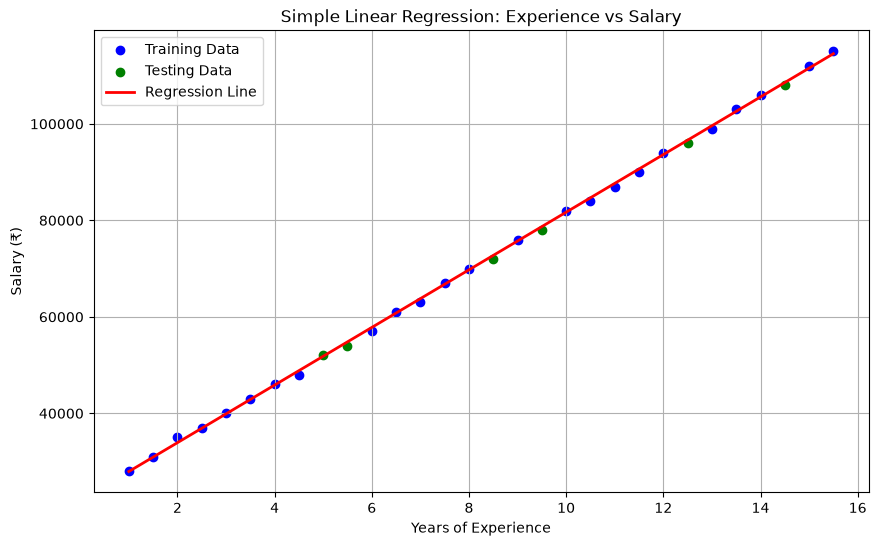

In [18]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_train,
    y_train,
    color="blue",
    label="Training Data"
)

plt.scatter(
    X_test,
    y_test,
    color="green",
    label="Testing Data"
)

plt.plot(
    X,
    model.predict(X),
    color="red",
    linewidth=2,
    label="Regression Line"
)

plt.title("Simple Linear Regression: Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary (₹)")
plt.legend()
plt.grid(True)

plt.show()

In [19]:
new_employee = pd.DataFrame({
    "YearsExperience": [12]
})

predicted_salary = model.predict(new_employee)

print(
    f"Predicted salary for 12 years of experience: "
    f"₹{predicted_salary[0]:,.2f}"
)

Predicted salary for 12 years of experience: ₹93,638.31
